# Análisis Exploratorio de Datos (EDA) — Plátanos

- **Estudiante:** Hans Andre Perez Sequeiros (`222184@unamba.edu.pe`)
- **Curso:** Fundamentos de Inteligencia Artificial (AIS85) — UNAMBA
- **Etapa CRISP-ML:** Comprensión de los datos (EDA)
- **Clases analizadas:** `freshbanana` (plátano fresco) y `rottenbanana` (plátano deteriorado)

En este cuaderno revisamos el conjunto completo (`train` + `test`), verificamos la integridad y los modos de color (`RGB` y `RGBA`), medimos las resoluciones, detectamos la repetición de capturas base entre particiones y exportamos las figuras para el artículo.

In [8]:
# 1. CONFIGURACIÓN DE RUTAS Y CARGA DE IMÁGENES (TRAIN + TEST)
from pathlib import Path

# Ubicamos automáticamente la carpeta 'dataset' sin tocar otros archivos
posibles_rutas = [
    Path.cwd().parent / 'dataset',
    Path.cwd() / 'dataset',
    Path(r'd:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\dataset'),
]

ruta_dataset = next((p for p in posibles_rutas if (p / 'train').exists() and (p / 'test').exists()), None)
if ruta_dataset is None:
    raise FileNotFoundError('No se encontró la carpeta dataset con subcarpetas train y test.')

# Carpeta donde guardaremos las figuras listas para Overleaf
ruta_figuras = Path.cwd() / 'figuras_paper'
ruta_figuras.mkdir(parents=True, exist_ok=True)

clases = ['freshbanana', 'rottenbanana']
extensiones = {'.png', '.jpg', '.jpeg'}

# Recolectamos únicamente train/ y test/ para evitar leer subcarpetas duplicadas como dataset/dataset
registros = []
for split in ['train', 'test']:
    for clase in clases:
        carpeta = ruta_dataset / split / clase
        for archivo in sorted(carpeta.iterdir()):
            if archivo.is_file() and archivo.suffix.lower() in extensiones:
                registros.append({
                    'ruta': str(archivo),
                    'archivo': archivo.name,
                    'split_original': split,
                    'clase': clase,
                })

print('Ruta del dataset:', ruta_dataset)
print('Total de imágenes encontradas (train + test):', len(registros))
print('Carpeta de figuras:', ruta_figuras)

Ruta del dataset: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\dataset
Total de imágenes encontradas (train + test): 4716
Carpeta de figuras: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\figuras_paper


In [9]:
# 2. IMPORTACIÓN DE LIBRERÍAS Y FUNCIÓN AUXILIAR DE LECTURA
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

random.seed(42)
np.random.seed(42)
sns.set_theme(style='whitegrid')

def cargar_rgb(ruta_img):
    """Carga una imagen en RGB; si tiene transparencia (RGBA), la coloca sobre fondo blanco."""
    with Image.open(ruta_img) as img:
        if img.mode == 'RGBA':
            fondo = Image.new('RGB', img.size, (255, 255, 255))
            fondo.paste(img, mask=img.split()[3])
            return np.array(fondo)
        return np.array(img.convert('RGB'))

def obtener_foto_base(nombre_archivo):
    """Extrae el identificador de la captura original ('Screen Shot ...') quitando prefijos de aumento."""
    if 'Screen Shot' in nombre_archivo:
        return 'Screen Shot' + nombre_archivo.split('Screen Shot')[-1]
    return nombre_archivo

df_eda = pd.DataFrame(registros)
df_eda['foto_base'] = df_eda['archivo'].apply(obtener_foto_base)
df_eda.head()

,ruta,archivo,split_original,clase,foto_base
0,d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\pro...,rotated_by_15_Screen Shot 2018-06-12 at 10.00....,train,freshbanana,Screen Shot 2018-06-12 at 10.00.00 PM.png
1,d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\pro...,rotated_by_15_Screen Shot 2018-06-12 at 10.00....,train,freshbanana,Screen Shot 2018-06-12 at 10.00.21 PM.png
2,d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\pro...,rotated_by_15_Screen Shot 2018-06-12 at 10.00....,train,freshbanana,Screen Shot 2018-06-12 at 10.00.37 PM.png
3,d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\pro...,rotated_by_15_Screen Shot 2018-06-12 at 10.00....,train,freshbanana,Screen Shot 2018-06-12 at 10.00.42 PM.png
4,d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\pro...,rotated_by_15_Screen Shot 2018-06-12 at 10.00....,train,freshbanana,Screen Shot 2018-06-12 at 10.00.49 PM.png


Distribución original en disco:
clase           freshbanana  rottenbanana  Total
split_original                                  
test                    381           530    911
train                  1581          2224   3805
Total                  1962          2754   4716

Capturas base únicas totales: 524
Capturas base presentes simultáneamente en train y test: 442 (84.35%)


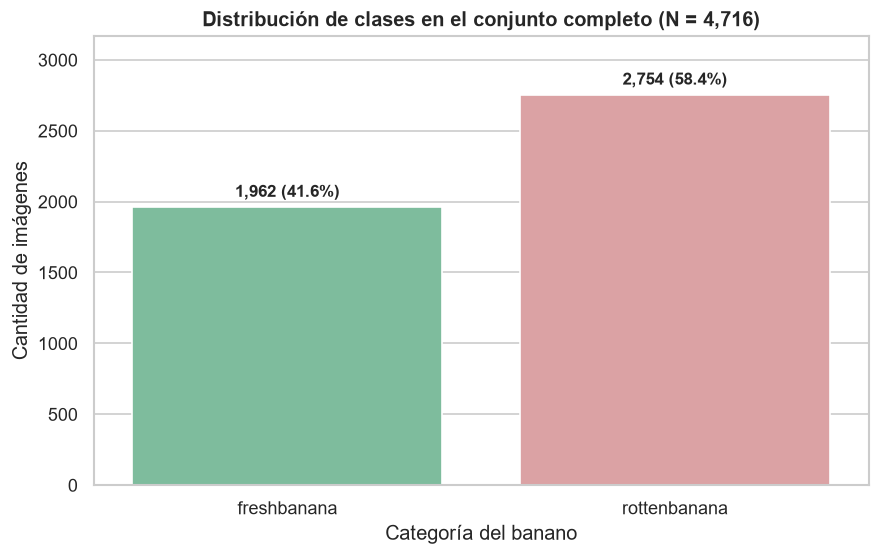

In [10]:
# 3. CONTEO DE CLASES, AUDITORÍA DE CAPTURAS BASE Y GRÁFICA DE DISTRIBUCIÓN
tabla_conteos = pd.crosstab(df_eda['split_original'], df_eda['clase'], margins=True, margins_name='Total')
print('Distribución original en disco:')
print(tabla_conteos)

# Verificamos si las mismas capturas originales aparecen en train y en test (fuga de datos)
bases_train = set(df_eda[df_eda['split_original'] == 'train']['foto_base'])
bases_test = set(df_eda[df_eda['split_original'] == 'test']['foto_base'])
bases_compartidas = bases_train & bases_test
print(f'\nCapturas base únicas totales: {df_eda["foto_base"].nunique()}')
print(f'Capturas base presentes simultáneamente en train y test: {len(bases_compartidas)} ({len(bases_compartidas)/df_eda["foto_base"].nunique()*100:.2f}%)')

conteo_clases = df_eda['clase'].value_counts().reindex(clases).reset_index()
conteo_clases.columns = ['Clase', 'Cantidad']

plt.figure(figsize=(7.5, 4.8))
ax = sns.barplot(
    data=conteo_clases,
    x='Clase',
    y='Cantidad',
    hue='Clase',
    palette=['#74c69d', '#e5989b'],
    legend=False
)
for p in ax.patches:
    altura = int(p.get_height())
    pct = altura / len(df_eda) * 100
    ax.annotate(
        f'{altura:,} ({pct:.1f}%)',
        (p.get_x() + p.get_width() / 2.0, altura),
        ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
        textcoords='offset points'
    )
plt.title(f'Distribución de clases en el conjunto completo (N = {len(df_eda):,})', fontsize=12, fontweight='bold')
plt.xlabel('Categoría del banano')
plt.ylabel('Cantidad de imágenes')
plt.ylim(0, conteo_clases['Cantidad'].max() * 1.15)
plt.tight_layout()
plt.savefig(ruta_figuras / 'fig_distribucion_clases.png', dpi=300, bbox_inches='tight')
plt.show()

Imágenes verificadas: 4,716 | Archivos corruptos: 0


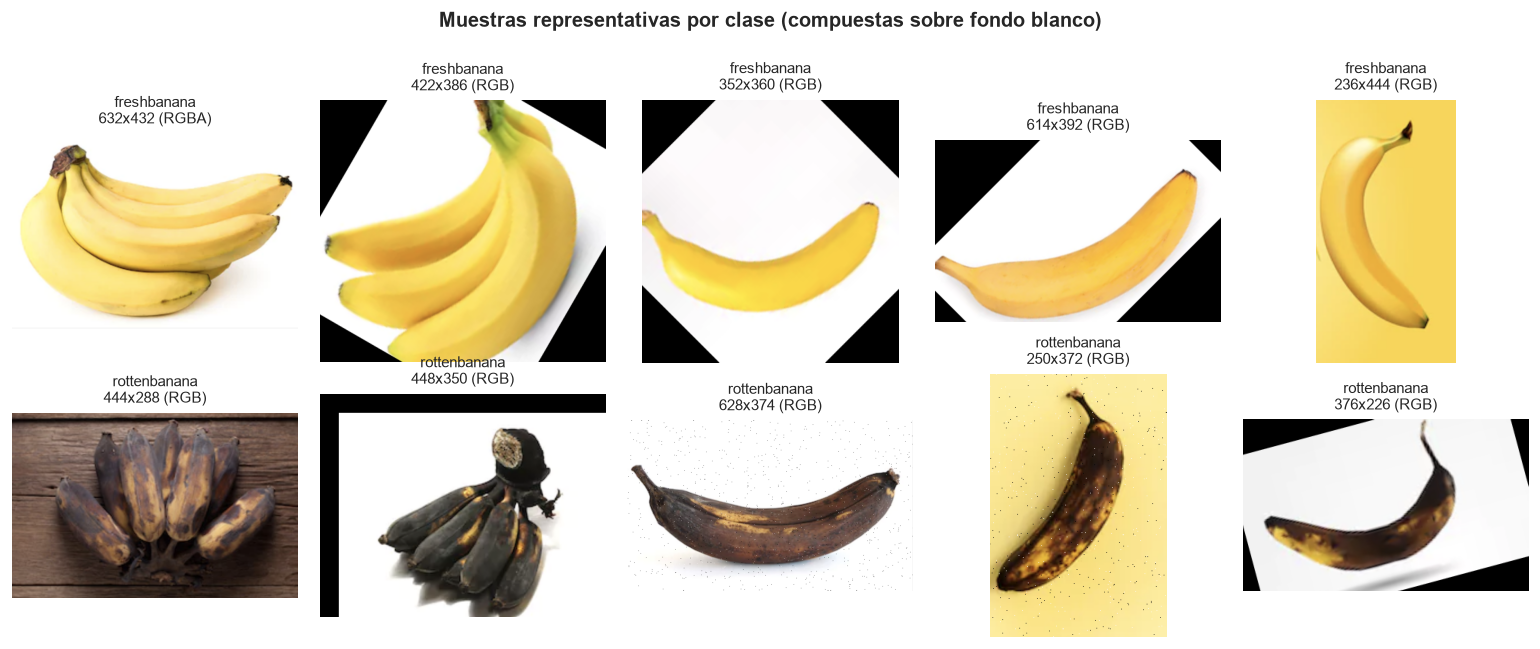

In [11]:
# 4. VERIFICACIÓN DE INTEGRIDAD Y VISUALIZACIÓN DE MUESTRAS ALEATORIAS
corruptas = []
for ruta in df_eda['ruta']:
    try:
        with Image.open(ruta) as img:
            img.verify()
    except Exception:
        corruptas.append(ruta)

print(f'Imágenes verificadas: {len(df_eda):,} | Archivos corruptos: {len(corruptas)}')

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for fila, clase in enumerate(clases):
    muestras = df_eda[df_eda['clase'] == clase].sample(n=5, random_state=42)
    for col, (_, row) in enumerate(muestras.iterrows()):
        with Image.open(row['ruta']) as im_info:
            modo = im_info.mode
            ancho, alto = im_info.size
        img_rgb = cargar_rgb(row['ruta'])
        ax = axes[fila, col]
        ax.imshow(img_rgb)
        ax.set_title(f'{clase}\n{ancho}x{alto} ({modo})', fontsize=9)
        ax.axis('off')

plt.suptitle('Muestras representativas por clase (compuestas sobre fondo blanco)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(ruta_figuras / 'fig_muestras_platanos.png', dpi=300, bbox_inches='tight')
plt.show()

Modos de color encontrados:
modo
RGB     4192
RGBA     524
Name: count, dtype: int64

Ancho (px) -> min: 174, media: 511.2, max: 862
Alto (px)  -> min: 128, media: 376.6, max: 518


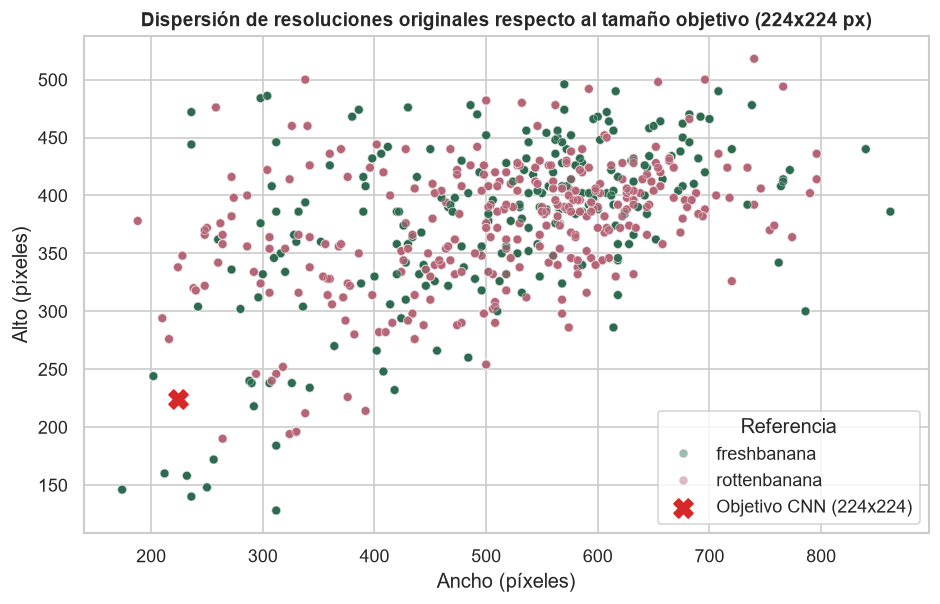

In [12]:
# 5. ANÁLISIS DE RESOLUCIONES Y MODOS DE COLOR EN TODO EL DATASET
anchos, altos, modos = [], [], []
for ruta in df_eda['ruta']:
    with Image.open(ruta) as img:
        w, h = img.size
        anchos.append(w)
        altos.append(h)
        modos.append(img.mode)

df_eda['ancho'] = anchos
df_eda['alto'] = altos
df_eda['modo'] = modos

print('Modos de color encontrados:')
print(df_eda['modo'].value_counts())
print(f"\nAncho (px) -> min: {df_eda['ancho'].min()}, media: {df_eda['ancho'].mean():.1f}, max: {df_eda['ancho'].max()}")
print(f"Alto (px)  -> min: {df_eda['alto'].min()}, media: {df_eda['alto'].mean():.1f}, max: {df_eda['alto'].max()}")

plt.figure(figsize=(8, 5.2))
sns.scatterplot(
    data=df_eda,
    x='ancho',
    y='alto',
    hue='clase',
    palette={'freshbanana': '#2d6a4f', 'rottenbanana': '#b56576'},
    alpha=0.45,
    s=28
)
plt.scatter([224], [224], color='#d62828', marker='X', s=130, zorder=5, label='Objetivo CNN (224x224)')
plt.title('Dispersión de resoluciones originales respecto al tamaño objetivo (224x224 px)', fontsize=11.5, fontweight='bold')
plt.xlabel('Ancho (píxeles)')
plt.ylabel('Alto (píxeles)')
plt.legend(title='Referencia')
plt.tight_layout()
plt.savefig(ruta_figuras / 'fig_resoluciones_platanos.png', dpi=300, bbox_inches='tight')
plt.show()

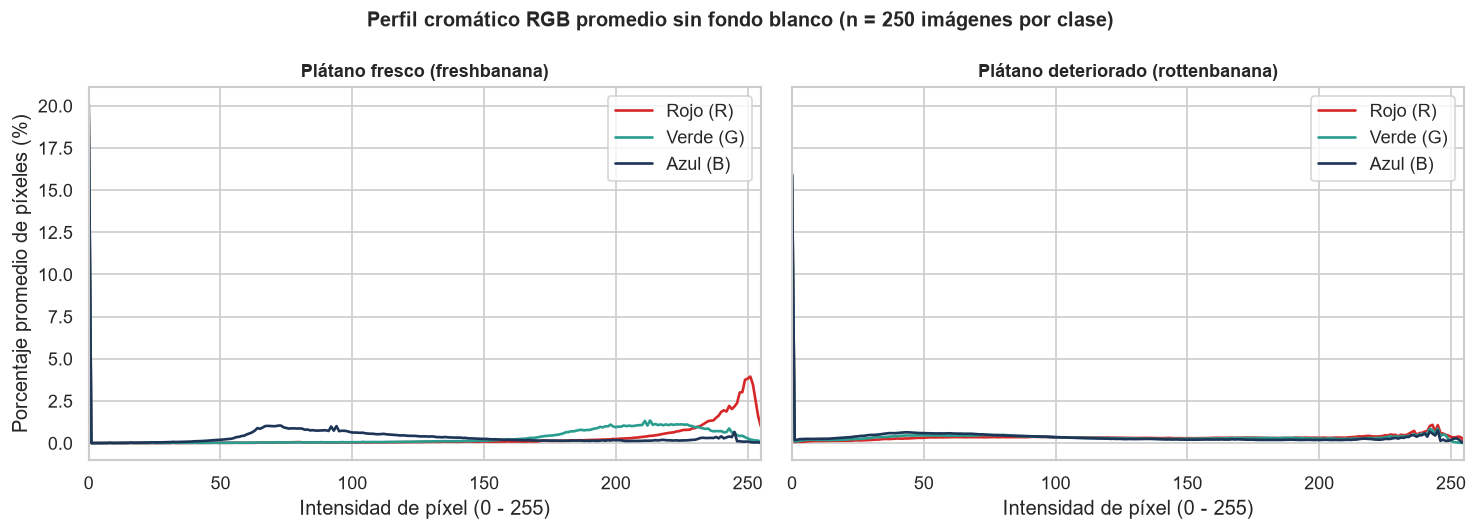

EDA completado. Figuras exportadas en: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\figuras_paper


In [13]:
# 6. HISTOGRAMA RGB PROMEDIO POR CLASE (EXCLUYENDO FONDO BLANCO)
def calcular_hist_promedio(sub_df):
    acum = np.zeros((256, 3), dtype=np.float64)
    for ruta in sub_df['ruta']:
        img = cargar_rgb(ruta)
        # Máscara para ignorar píxeles blancos casi puros del fondo
        mascara = (~((img[:, :, 0] > 245) & (img[:, :, 1] > 245) & (img[:, :, 2] > 245))).astype(np.uint8) * 255
        for c in range(3):
            hist = cv2.calcHist([img], [c], mascara, [256], [0, 256]).flatten()
            if hist.sum() > 0:
                hist = hist / hist.sum() * 100.0
            acum[:, c] += hist
    return acum / len(sub_df)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharey=True)
canales = [('Rojo (R)', '#d62828'), ('Verde (G)', '#2a9d8f'), ('Azul (B)', '#1d3557')]
titulos = {'freshbanana': 'Plátano fresco (freshbanana)', 'rottenbanana': 'Plátano deteriorado (rottenbanana)'}

for ax, clase in zip(axes, clases):
    muestra_hist = df_eda[df_eda['clase'] == clase].sample(n=250, random_state=42)
    hist_prom = calcular_hist_promedio(muestra_hist)
    for idx_c, (nombre_c, color_c) in enumerate(canales):
        ax.plot(range(256), hist_prom[:, idx_c], color=color_c, linewidth=1.6, label=nombre_c)
    ax.set_title(titulos[clase], fontsize=11, fontweight='bold')
    ax.set_xlabel('Intensidad de píxel (0 - 255)')
    ax.set_xlim(0, 255)
    ax.legend()

axes[0].set_ylabel('Porcentaje promedio de píxeles (%)')
plt.suptitle('Perfil cromático RGB promedio sin fondo blanco (n = 250 imágenes por clase)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(ruta_figuras / 'fig_histograma_rgb.png', dpi=300, bbox_inches='tight')
plt.show()

print('EDA completado. Figuras exportadas en:', ruta_figuras)